**Library** **Imports**

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os
import itertools


from glob import glob
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import plot_model


**Loading and Exploring the Dataset**

In [59]:
df = pd.read_csv('skin_cancer.csv')
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB


In [61]:
df.shape

(10015, 7)

In [64]:
import zipfile
import os

# Create a directory to store all extracted images
os.makedirs("skin_cancer_images", exist_ok=True)

# Extract part 1 of the dataset
with zipfile.ZipFile("skin_cancer_images_part_1.zip", 'r') as zip_ref:
    zip_ref.extractall("skin_cancer_images")

# Extract part 2 of the dataset
with zipfile.ZipFile("skin_cancer_images_part_2.zip", 'r') as zip_ref:
    zip_ref.extractall("skin_cancer_images")


In [25]:
import zipfile
import os

# ساخت پوشه نهایی برای همه تصاویر
os.makedirs("skin_cancer_images", exist_ok=True)

# استخراج part 1
with zipfile.ZipFile("HAM10000_images_part_1.zip", 'r') as zip_ref:
    zip_ref.extractall("HAM10000_images")

# استخراج part 2
with zipfile.ZipFile("HAM10000_images_part_2.zip", 'r') as zip_ref:
    zip_ref.extractall("HAM10000_images")


Data Preprocessing

In [67]:
# Mapping of lesion codes to their corresponding full names
lesion_labels = {
    'nv':  'Nevi (melanocytic)',
    'mel': 'Skin Melanoma',
    'bkl': 'Benign keratosis-like',
    'bcc': 'Basal Cell Carcinoma',
    'akiec': 'Actinic Keratosis',
    'vasc': 'Vascular Lesion',
    'df':   'Dermatofibroma Tumor'
}

# Define the directory containing extracted skin lesion images
image_directory = 'skin_cancer_images'


In [65]:
lesion_type_dict = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}


base_skin_dir = 'skin_cancer_images'

In [68]:
imageid_path_dict = {
    os.path.splitext(os.path.basename(x))[0]: x
    for x in glob(os.path.join(base_skin_dir, '*.jpg'))
}

**Feature Enhancement via New Columns**

In [74]:
df['path'] = df['image_id'].map(imageid_path_dict.get)
df['cell_type'] = df['dx'].map(lesion_type_dict.get)
df['cell_type_idx'] = pd.Categorical(df['cell_type']).codes

df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,path,cell_type,cell_type_idx
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,skin_cancer_images/ISIC_0027419.jpg,Benign keratosis-like lesions,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,skin_cancer_images/ISIC_0025030.jpg,Benign keratosis-like lesions,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,skin_cancer_images/ISIC_0026769.jpg,Benign keratosis-like lesions,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,skin_cancer_images/ISIC_0025661.jpg,Benign keratosis-like lesions,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,skin_cancer_images/ISIC_0031633.jpg,Benign keratosis-like lesions,2


In [70]:
df.isna().sum()

,0
lesion_id,0
image_id,0
dx,0
dx_type,0
age,57
sex,0
localization,0
path,0
cell_type,0
cell_type_idx,0


In [71]:
df['age'] = df['age'].fillna(df['age'].mean())


In [72]:
df.isna().sum().sum()

np.int64(0)

In [73]:
df.isna().sum()


,0
lesion_id,0
image_id,0
dx,0
dx_type,0
age,0
sex,0
localization,0
path,0
cell_type,0
cell_type_idx,0


**Exploratory Data Analysis**

/tmp/ipython-input-2959378701.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  gender_plot = sns.countplot(


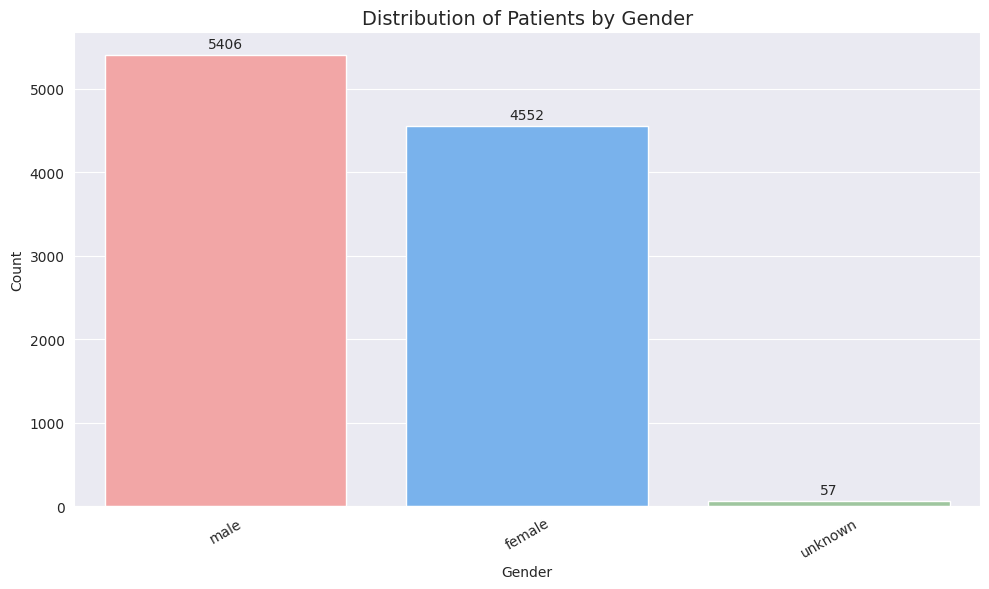

In [75]:
# Apply a different style for visualization
sns.set_style('darkgrid')

# Custom color palette
custom_colors = ['#FF9999', '#66B2FF', '#99CC99']  # soft red, blue, green

# Create figure and axis
plt.figure(figsize=(10, 6))

# Draw count plot for gender distribution
gender_plot = sns.countplot(
    data=df,
    x='sex',
    palette=custom_colors
)

# Annotate each bar with its value
for bar in gender_plot.containers:
    gender_plot.bar_label(bar, padding=3)

# Customize plot appearance
plt.title('Distribution of Patients by Gender', fontsize=14)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Impact of Cell Types on Patients**

/tmp/ipython-input-2191296846.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  cell_plot = sns.countplot(


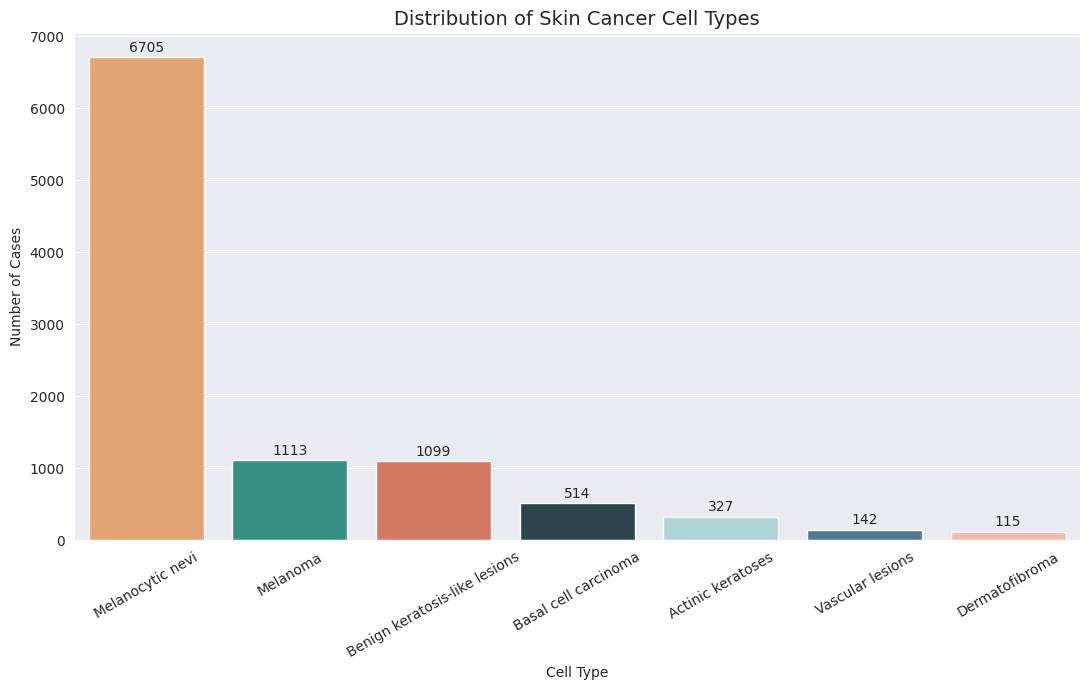

In [76]:
# Set a different plot style
sns.set_style('darkgrid')

# Define a custom color palette
new_colors = ['#f4a261', '#2a9d8f', '#e76f51', '#264653', '#a8dadc', '#457b9d', '#ffb4a2']

# Create the figure
plt.figure(figsize=(11, 7))

# Plot the count of different cell types
cell_plot = sns.countplot(
    data=df,
    x='cell_type',
    order=df['cell_type'].value_counts().index,
    palette=new_colors
)

# Annotate bar values
for bars in cell_plot.containers:
    cell_plot.bar_label(bars, padding=2)

# Add titles and formatting
plt.title('Distribution of Skin Cancer Cell Types', fontsize=14)
plt.xlabel('Cell Type')
plt.ylabel('Number of Cases')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Distribution of Skin Cancer Cell Types by Gender**

/tmp/ipython-input-2755521483.py:11: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  gender_cell_plot = sns.countplot(


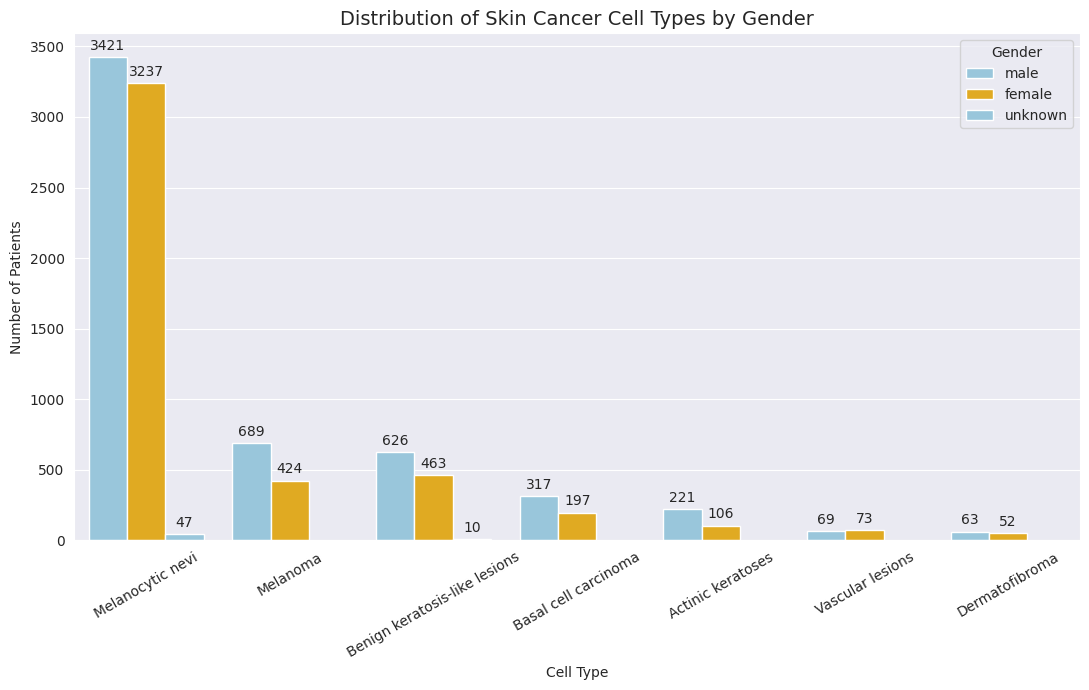

In [77]:
# Apply a clean background style
sns.set_style('darkgrid')

# Define custom color palette for genders
gender_colors = ['#8ecae6', '#ffb703']  # blue and orange

# Set up the figure
plt.figure(figsize=(11, 7))

# Plot cell type distribution split by gender
gender_cell_plot = sns.countplot(
    data=df,
    x='cell_type',
    hue='sex',
    order=df['cell_type'].value_counts().index,
    palette=gender_colors
)

# Annotate bar values
for bars in gender_cell_plot.containers:
    gender_cell_plot.bar_label(bars, padding=3)

# Customize plot appearance
plt.title('Distribution of Skin Cancer Cell Types by Gender', fontsize=14)
plt.xlabel('Cell Type')
plt.ylabel('Number of Patients')
plt.xticks(rotation=30)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()


**Type of Skin Cancer Cell**

/tmp/ipython-input-3096254606.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  diagnosis_plot = sns.countplot(


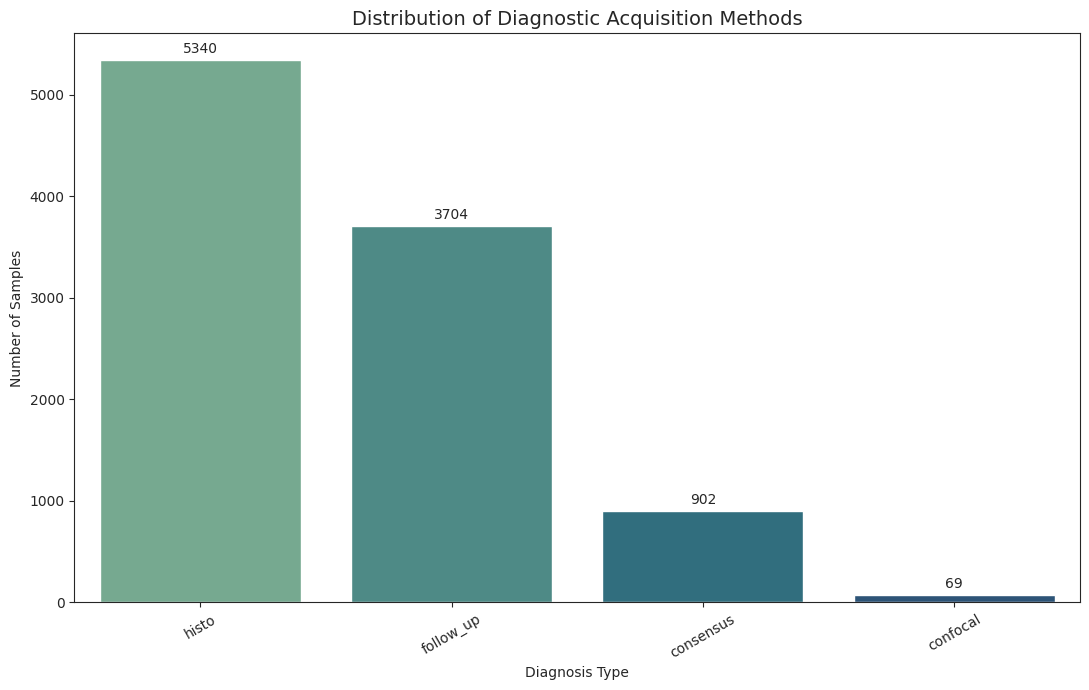

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

# Apply a clean visual theme
sns.set_style('ticks')

# Set figure size
plt.figure(figsize=(11, 7))

# Plot the frequency of diagnosis types
diagnosis_plot = sns.countplot(
    data=df,
    x='dx_type',
    order=df['dx_type'].value_counts().index,
    palette='crest'  # changed from 'flare' to 'crest'
)

# Add labels on top of each bar
for bars in diagnosis_plot.containers:
    diagnosis_plot.bar_label(bars, padding=3)

# Customize plot appearance
plt.title('Distribution of Diagnostic Acquisition Methods', fontsize=14)
plt.xlabel('Diagnosis Type')
plt.ylabel('Number of Samples')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Distribution of Cell Types Across Genders**

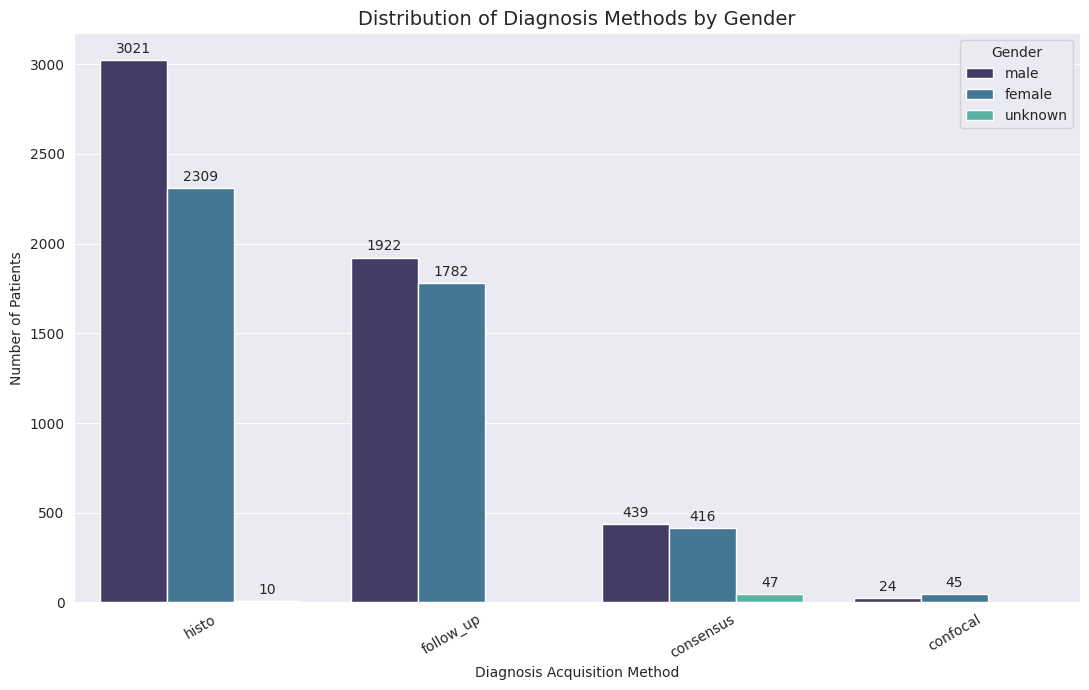

In [79]:
# Apply visual style
sns.set_style('darkgrid')

# Set up the figure
plt.figure(figsize=(11, 7))

# Plot diagnosis acquisition methods grouped by gender
diagnosis_gender_plot = sns.countplot(
    data=df,
    x='dx_type',
    hue='sex',
    order=df['dx_type'].value_counts().index,
    palette='mako'  # Changed from 'flare' to 'mako'
)

# Annotate bars with their heights
for bars in diagnosis_gender_plot.containers:
    diagnosis_gender_plot.bar_label(bars, padding=3)

# Customize appearance
plt.title('Distribution of Diagnosis Methods by Gender', fontsize=14)
plt.xlabel('Diagnosis Acquisition Method')
plt.ylabel('Number of Patients')
plt.xticks(rotation=30)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()


**Distribution of Lesions by Body Site**

/tmp/ipython-input-3703177381.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  body_site_plot = sns.countplot(


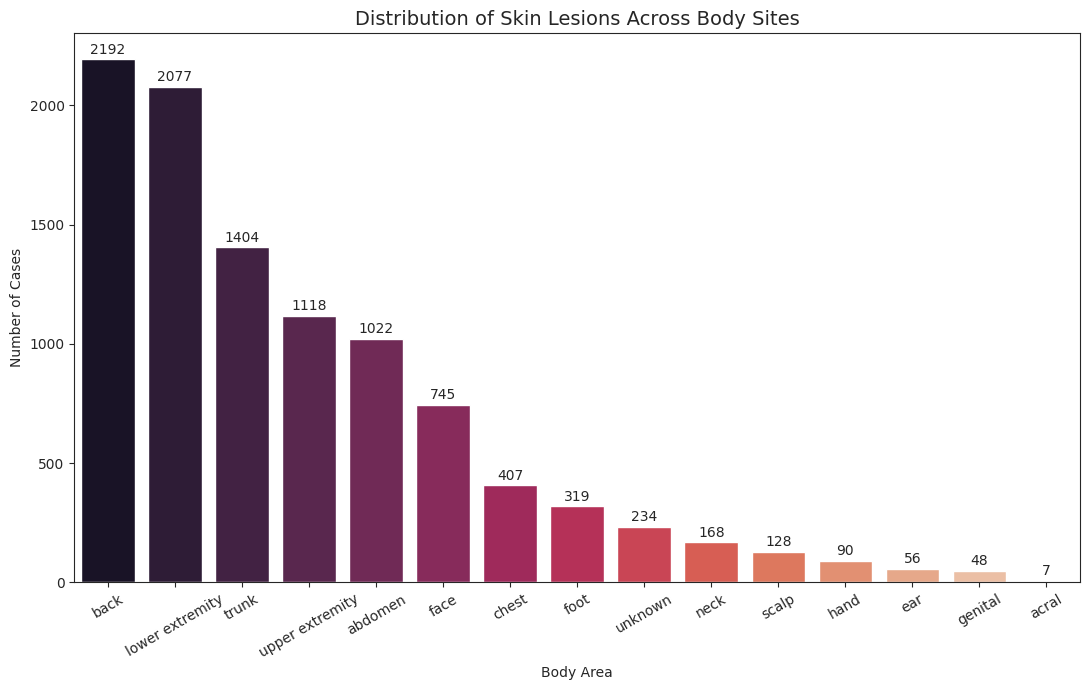

In [80]:
# Set a custom plot style
sns.set_style('ticks')

# Initialize the figure
plt.figure(figsize=(11, 7))

# Plot the count of lesion localizations
body_site_plot = sns.countplot(
    data=df,
    x='localization',
    order=df['localization'].value_counts().index,
    palette='rocket'  # changed from 'crest' to 'rocket'
)

# Add labels to each bar
for bars in body_site_plot.containers:
    body_site_plot.bar_label(bars, padding=2)

# Plot title and formatting
plt.title('Distribution of Skin Lesions Across Body Sites', fontsize=14)
plt.xlabel('Body Area')
plt.ylabel('Number of Cases')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Comparison of Lesion Locations Between Genders**

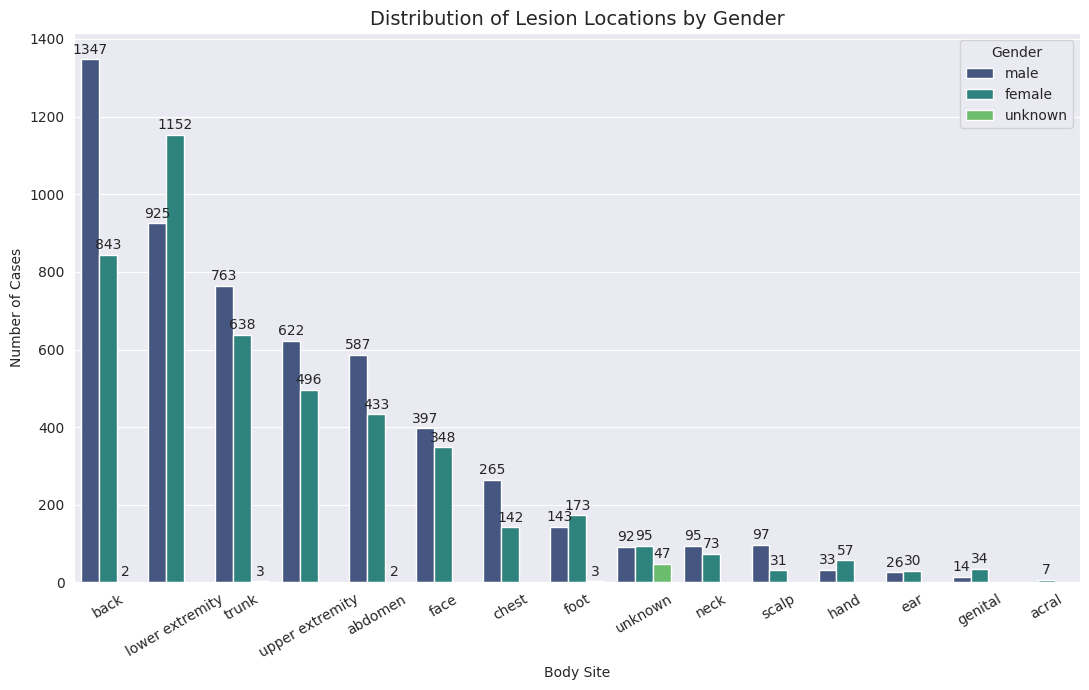

In [81]:
# Apply a minimal style to the plot
sns.set_style('darkgrid')

# Create the figure with custom size
plt.figure(figsize=(11, 7))

# Plot localization counts by gender
location_by_gender_plot = sns.countplot(
    data=df,
    x='localization',
    hue='sex',
    order=df['localization'].value_counts().index,
    palette='viridis'  # changed from 'crest' to 'viridis'
)

# Add value labels on top of bars
for group in location_by_gender_plot.containers:
    location_by_gender_plot.bar_label(group, padding=2)

# Add title and axis labels
plt.title('Distribution of Lesion Locations by Gender', fontsize=14)
plt.xlabel('Body Site')
plt.ylabel('Number of Cases')
plt.xticks(rotation=30)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()


**Age**

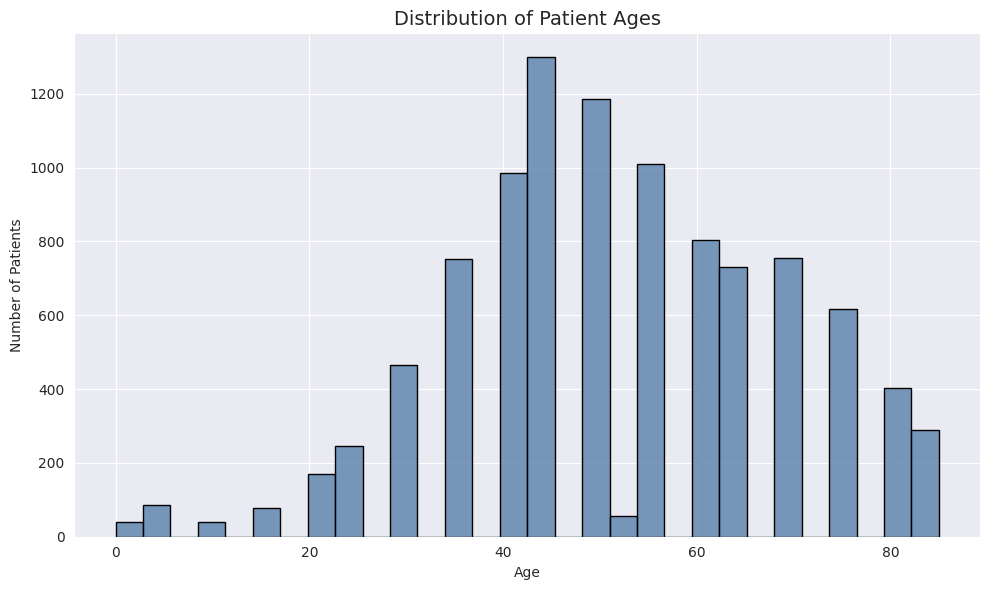

In [82]:
# Set a dark background for contrast
sns.set_style('darkgrid')

# Create figure with custom size
plt.figure(figsize=(10, 6))

# Plot age distribution as a histogram
age_plot = sns.histplot(
    data=df,
    x='age',
    bins=30,
    color='#4e79a7',  # custom blue color
    edgecolor='black'
)

# Add titles and labels
plt.title('Distribution of Patient Ages', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()


**Distribution of Patient Age Across Genders**

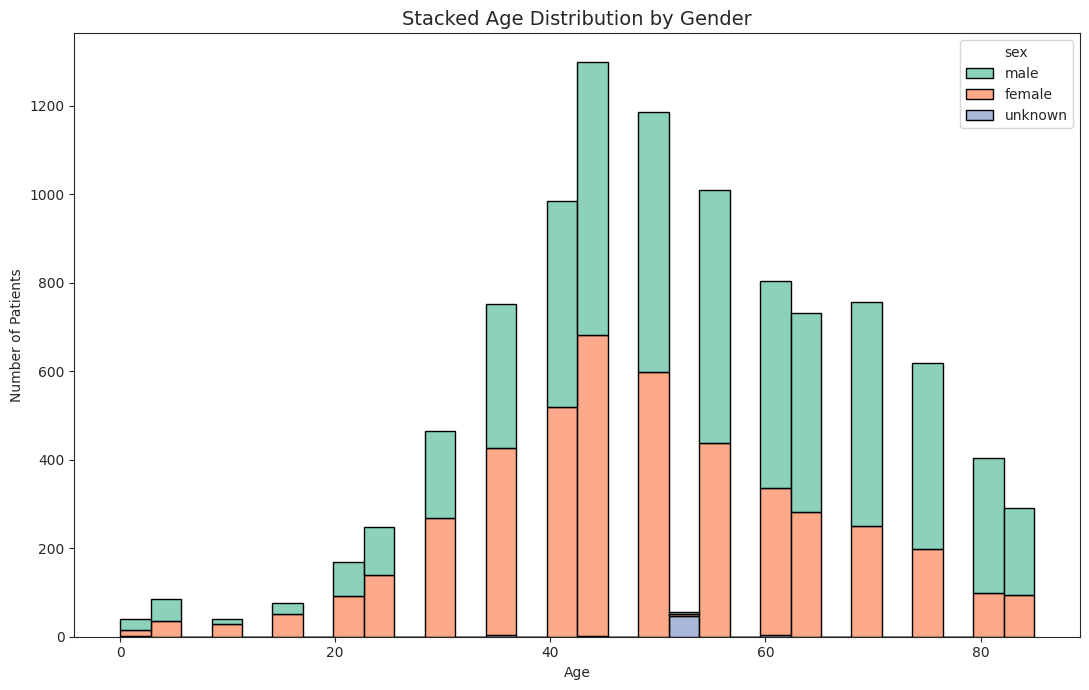

In [83]:
# Use a clean style
sns.set_style('ticks')

# Initialize the figure
plt.figure(figsize=(11, 7))

# Plot age distribution by gender using stacked histogram
sns.histplot(
    data=df,
    x='age',
    hue='sex',
    multiple='stack',
    bins=30,
    palette='Set2',
    edgecolor='black'
)

# Add title and axis labels
plt.title('Stacked Age Distribution by Gender', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()


**Age Distribution by Localization Area**

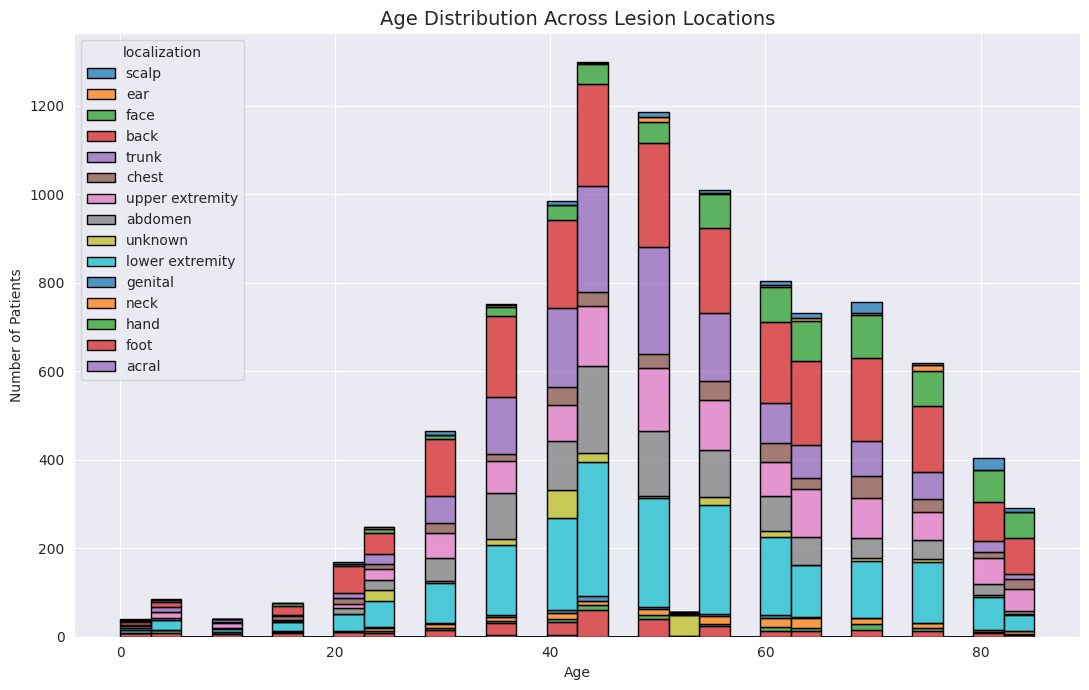

In [84]:
# Use a clean visual style
sns.set_style('darkgrid')

# Set up the figure
plt.figure(figsize=(11, 7))

# Plot age distribution stacked by localization area
sns.histplot(
    data=df,
    x='age',
    hue='localization',
    multiple='stack',
    bins=30,
    palette='tab10',
    edgecolor='black'
)

# Add title and axis labels
plt.title('Age Distribution Across Lesion Locations', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()


In [86]:
df['image'] = df['path'].map(lambda x: np.asarray(Image.open(x).resize((100,75))))

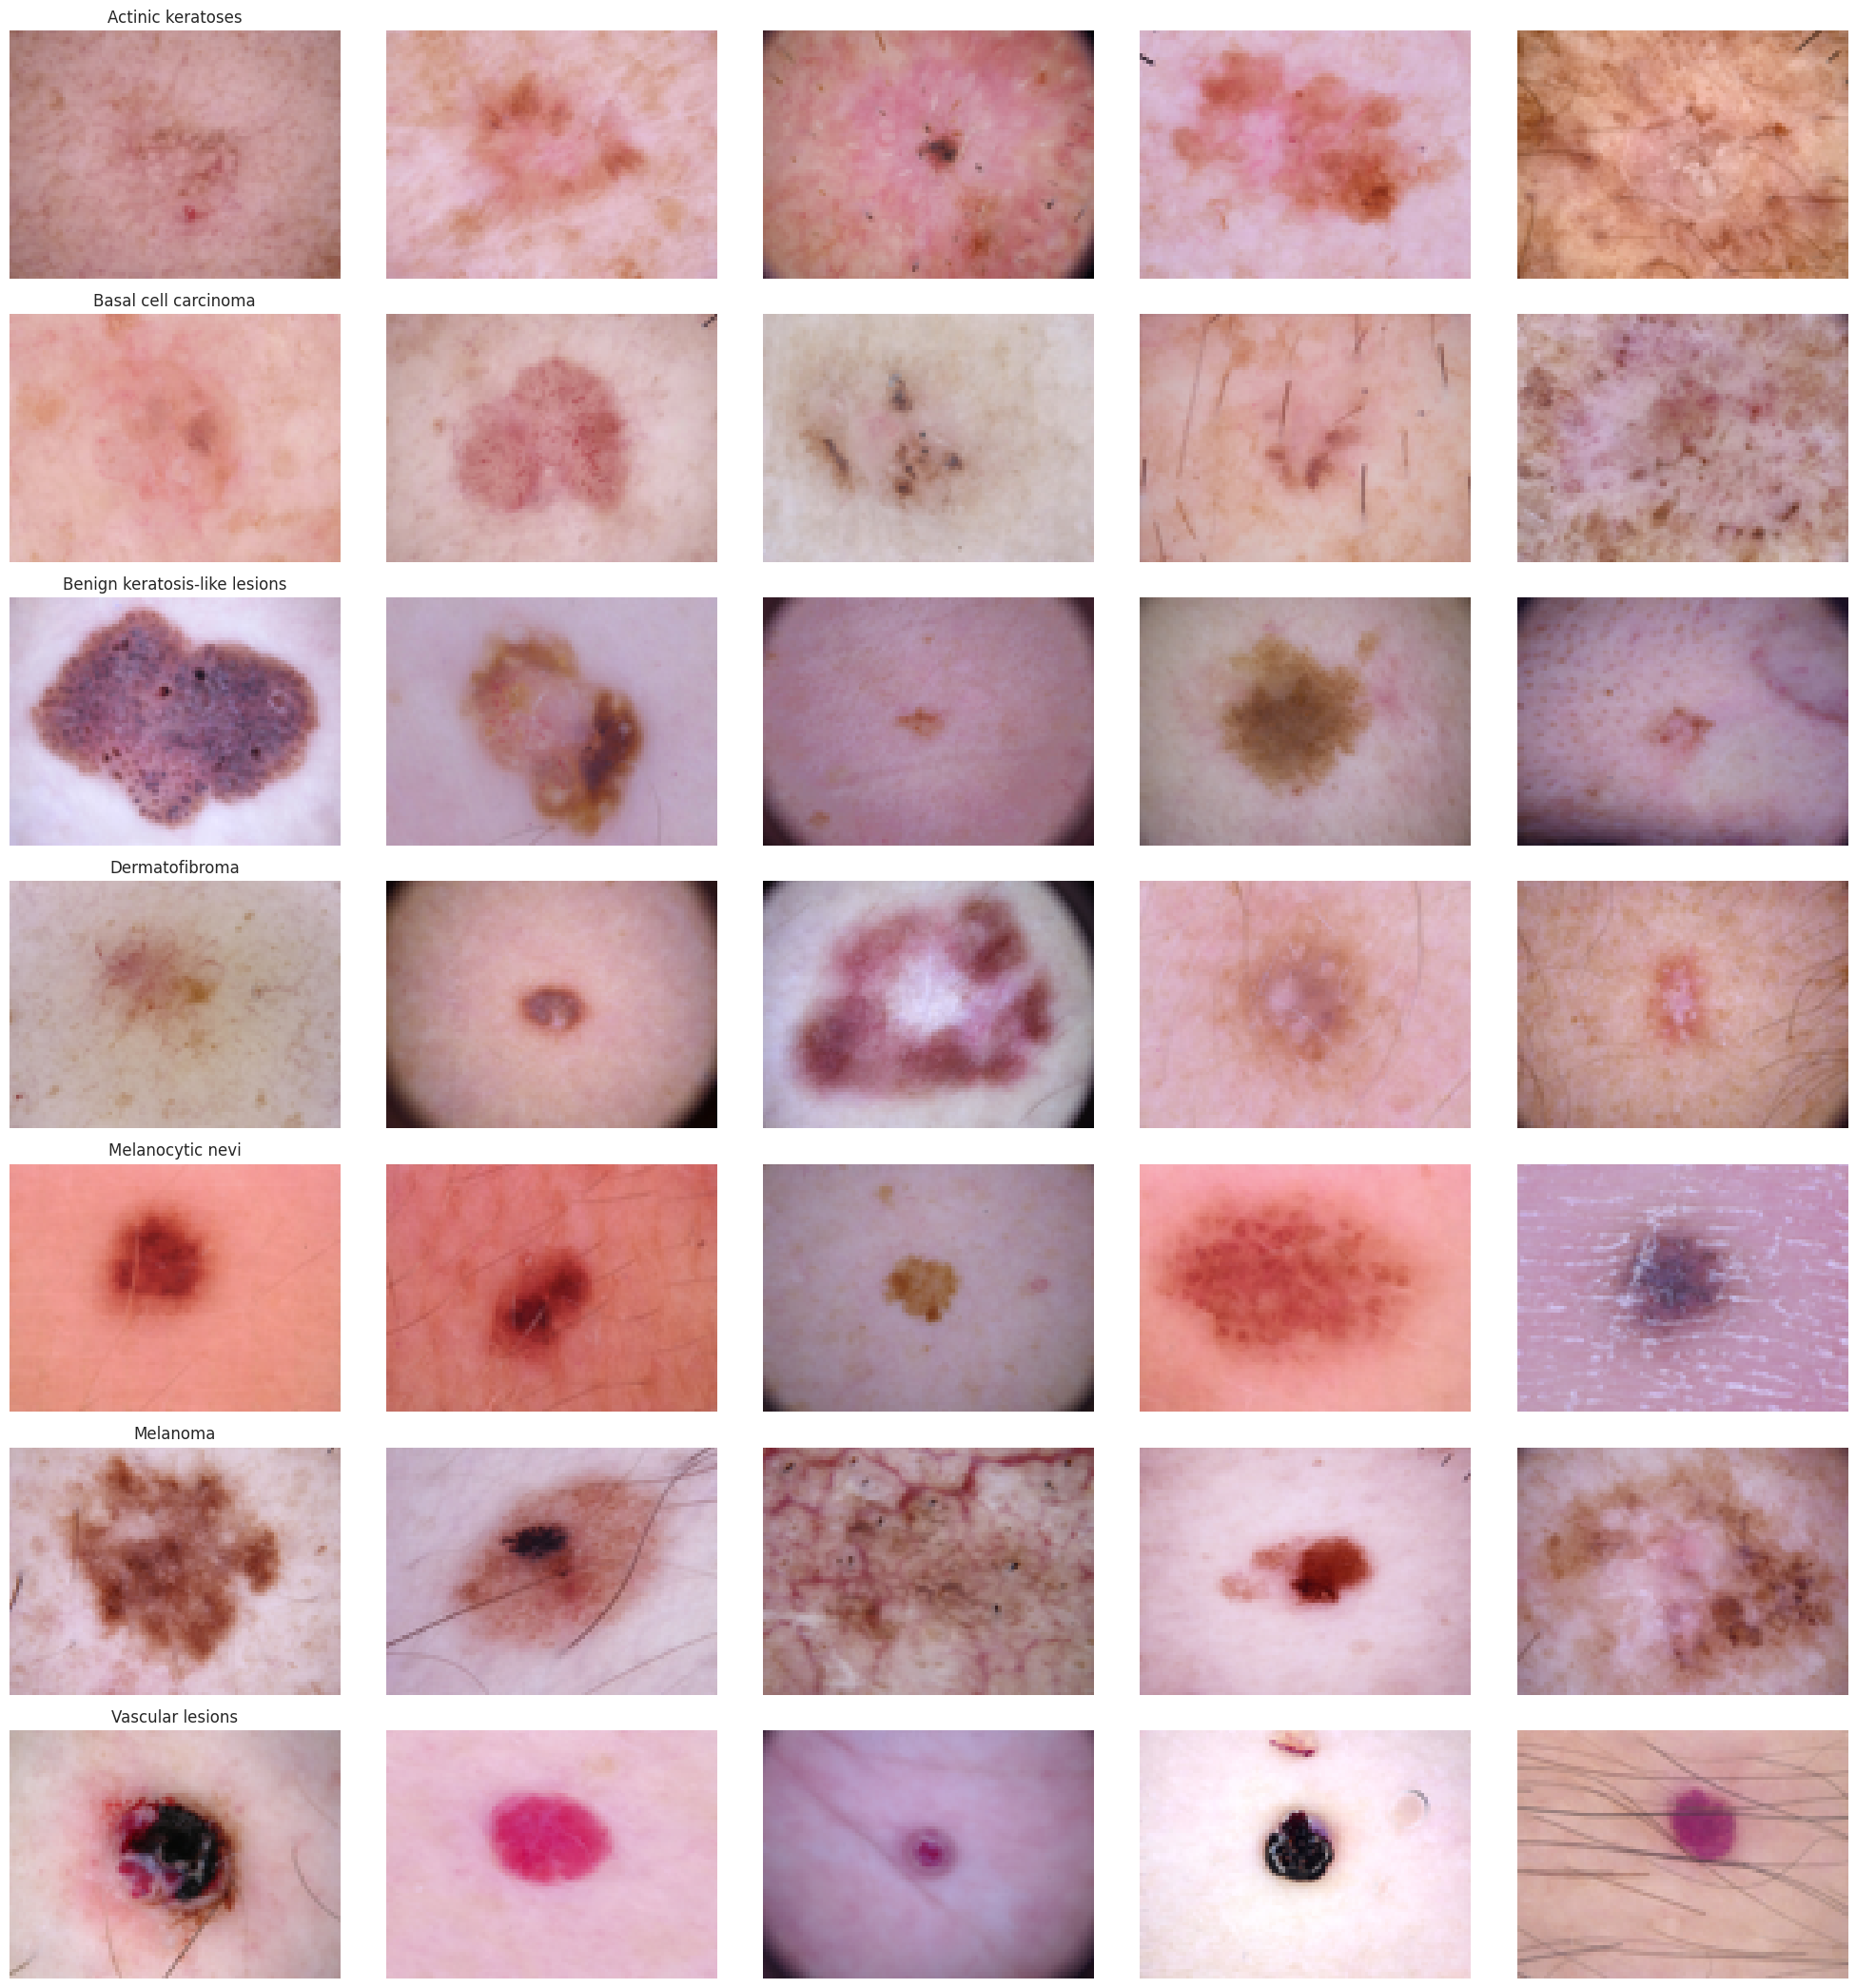

In [87]:
# Number of samples per category
samples_per_class = 5
unique_classes = df['cell_type'].nunique()

# Set up the figure
fig, axes = plt.subplots(
    unique_classes, samples_per_class,
    figsize=(samples_per_class * 4, unique_classes * 3)
)

# Loop through each class and display sample images
for ax_row, (label, group) in zip(axes, df.sort_values('cell_type').groupby('cell_type')):
    ax_row[0].set_title(label, fontsize=12)

    # Randomly sample images for this cell type
    for ax, (_, row) in zip(ax_row, group.sample(samples_per_class, random_state=42).iterrows()):
        ax.imshow(row['image'])
        ax.axis('off')

# Adjust layout and save the figure
plt.tight_layout()
fig.savefig('cell_type_samples_grid.png', dpi=300)
plt.show()


**Analyzing Image Size Distribution**

In [88]:
df['image'].map(lambda x: x.shape).value_counts()

,count
image,
"(75, 100, 3)",10015


**Model Development**

In [89]:
# Separate input features and target labels
X = df.loc[:, df.columns != 'cell_type_idx']
y = df['cell_type_idx']

In [90]:
# Split the dataset into training and testing sets (80/20 split)
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=1234,
    shuffle=True
)


**Image Normalization**

In [91]:
# Convert image column to NumPy arrays
X_train = np.stack(x_train_o['image'].values)
X_test = np.stack(x_test_o['image'].values)

# Compute mean and std from training data
mean_train = X_train.mean()
std_train = X_train.std()

# Standardize both training and test data using training statistics
X_train = (X_train - mean_train) / std_train
X_test = (X_test - mean_train) / std_train  # use training stats only


**One-Hot Encoding of Labels**

In [92]:
# Convert target labels to one-hot encoded vectors
Y_train = to_categorical(y_train_o, num_classes=7)
Y_test = to_categorical(y_test_o, num_classes=7)


**Train-Validation Split**

In [93]:
# Split the training set further to create a validation set
X_train, X_val, Y_train, Y_val = train_test_split(
    X_train, Y_train,
    test_size=0.1,
    random_state=2,
    shuffle=True
)


In [94]:
# Reshape image arrays to 4D tensors: (samples, height, width, channels)
IMG_HEIGHT, IMG_WIDTH, CHANNELS = 75, 100, 3

x_train = x_train.reshape(-1, IMG_HEIGHT, IMG_WIDTH, CHANNELS)
x_test = x_test.reshape(-1, IMG_HEIGHT, IMG_WIDTH, CHANNELS)
x_validate = x_validate.reshape(-1, IMG_HEIGHT, IMG_WIDTH, CHANNELS)


**Defining the CNN Architecture**

In [52]:
# my CNN architechture is In -> [[Conv2D->relu]*2 -> MaxPool2D -> Dropout]*2 -> Flatten -> Dense -> Dropout -> Out
input_shape = (75, 100, 3)
num_classes = 7

model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3),activation='relu',padding = 'Same',input_shape=input_shape))
model.add(Conv2D(32,kernel_size=(3, 3), activation='relu',padding = 'Same',))
model.add(MaxPool2D(pool_size = (2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), activation='relu',padding = 'Same'))
model.add(Conv2D(64, (3, 3), activation='relu',padding = 'Same'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Dropout(0.40))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 75, 100, 32)    │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 100, 32)    │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 37, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 37, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 37, 50, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 18, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 18, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,686,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,752,999 (14.32 MB)

 Trainable params: 3,752,999 (14.32 MB)

 Non-trainable params: 0 (0.00 B)

In [95]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Define the optimizer with updated parameters
optimizer = Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, amsgrad=False)

# Compile the model with categorical crossentropy loss and accuracy metric
model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])

# Learning rate scheduler: reduce LR when validation accuracy stops improving
learning_rate_reduction = ReduceLROnPlateau(
    monitor='val_accuracy',  # Use 'val_accuracy' in newer versions instead of 'val_acc'
    patience=3,
    verbose=1,
    factor=0.5,
    min_lr=1e-5  # Minimum learning rate allowed
)


In [55]:
datagen = ImageDataGenerator(
        featurewise_center=False,  # set input mean to 0 over the dataset
        samplewise_center=False,  # set each sample mean to 0
        featurewise_std_normalization=False,  # divide inputs by std of the dataset
        samplewise_std_normalization=False,  # divide each input by its std
        zca_whitening=False,  # apply ZCA whitening
        rotation_range=10,  # randomly rotate images in the range (degrees, 0 to 180)
        zoom_range = 0.1, # Randomly zoom image
        width_shift_range=0.1,  # randomly shift images horizontally (fraction of total width)
        height_shift_range=0.1,  # randomly shift images vertically (fraction of total height)
        horizontal_flip=False,  # randomly flip images
        vertical_flip=False)  # randomly flip images

datagen.fit(x_train)

In [57]:
history = model.fit(
    datagen.flow(x_train, y_train, batch_size=batch_size),
    epochs=epochs,
    validation_data=(x_validate, y_validate),
    verbose=1,
    steps_per_epoch=x_train.shape[0] // batch_size,
    callbacks=[learning_rate_reduction]
)


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
721/721 ━━━━━━━━━━━━━━━━━━━━ 329s 451ms/step - accuracy: 0.6594 - loss: 1.1086 - val_accuracy: 0.6658 - val_loss: 0.9137 - learning_rate: 0.0010
Epoch 2/50
721/721 ━━━━━━━━━━━━━━━━━━━━ 384s 454ms/step - accuracy: 0.6678 - loss: 0.9286 - val_accuracy: 0.7020 - val_loss: 0.8786 - learning_rate: 0.0010
Epoch 3/50
721/721 ━━━━━━━━━━━━━━━━━━━━ 387s 461ms/step - accuracy: 0.6798 - loss: 0.8958 - val_accuracy: 0.7020 - val_loss: 0.8553 - learning_rate: 0.0010
Epoch 4/50
721/721 ━━━━━━━━━━━━━━━━━━━━ 374s 450ms/step - accuracy: 0.6886 - loss: 0.8610 - val_accuracy: 0.7070 - val_loss: 0.8009 - learning_rate: 0.0010
Epoch 5/50
721/721 ━━━━━━━━━━━━━━━━━━━━ 390s 461ms/step - accuracy: 0.6978 - loss: 0.8320 - val_accuracy: 0.7207 - val_loss: 0.7845 - learning_rate: 0.0010
Epoch 6/50
721/721 ━━━━━━━━━━━━━━━━━━━━ 322s 446ms/step - accuracy: 0.7056 - loss: 0.8322 - val_accuracy: 0.7195 - val_loss: 0.7335 - learning_rate: 0.0010
Epoch 7/50
721/721 ━━━━━━━━━━━━━━━━━━━━ 326s 451ms/step - accura

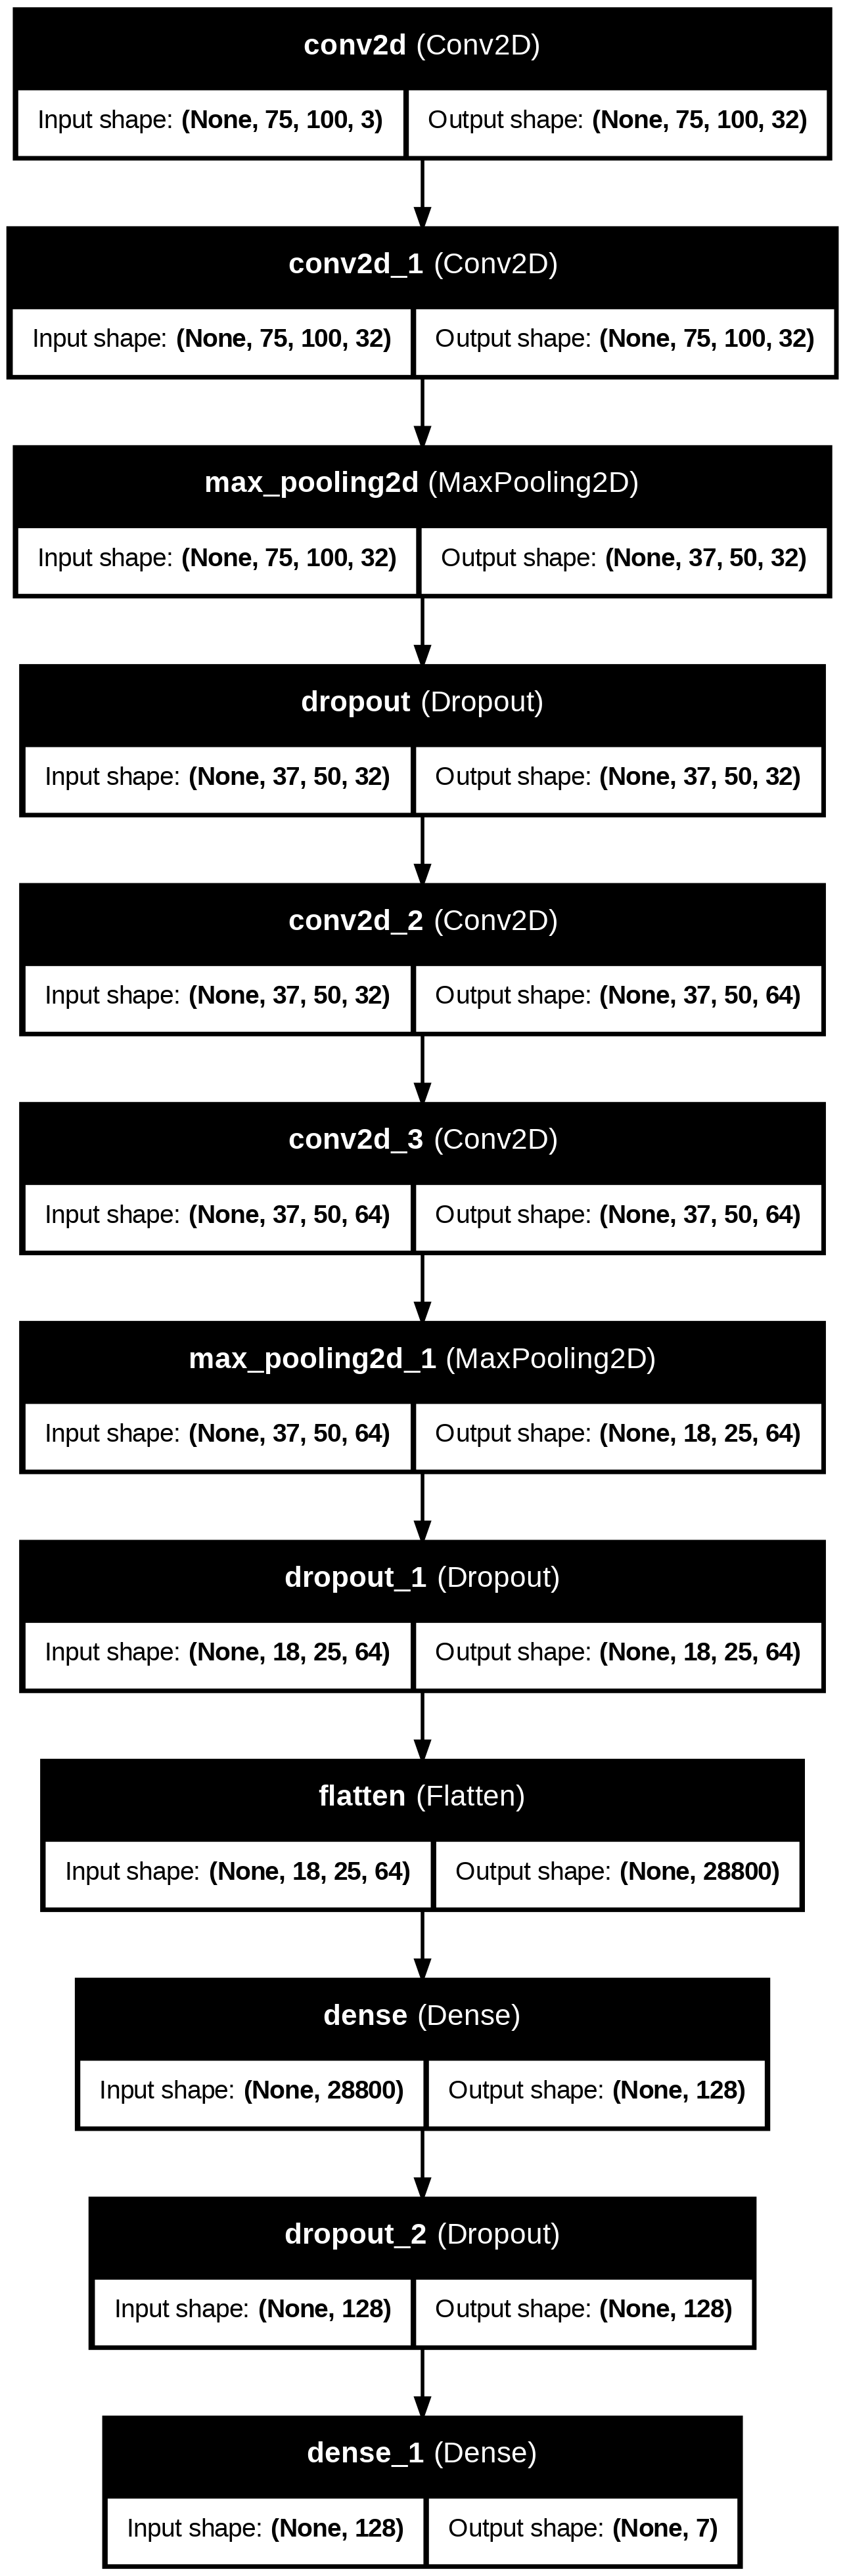

In [58]:
from tensorflow.keras.utils import plot_model

# Save a visual representation of the model architecture
plot_model(
    model,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True
)


**Model Accuracy**

In [96]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)

# Evaluate the model on the validation set
loss_v, accuracy_v = model.evaluate(x_validate, y_validate, verbose=1)

# Print validation results
print("Validation: accuracy = %f  ;  loss_v = %f" % (accuracy_v, loss_v))

# Print test results
print("Test: accuracy = %f  ;  loss = %f" % (accuracy, loss))

# Save the trained model to a file
model.save("model.h5")


63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 314ms/step - accuracy: 0.7838 - loss: 0.6308
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 252ms/step - accuracy: 0.8064 - loss: 0.5805


Validation: accuracy = 0.781796  ;  loss_v = 0.607475
Test: accuracy = 0.773340  ;  loss = 0.642443


**Confusion Matrix Visualization**

26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 272ms/step


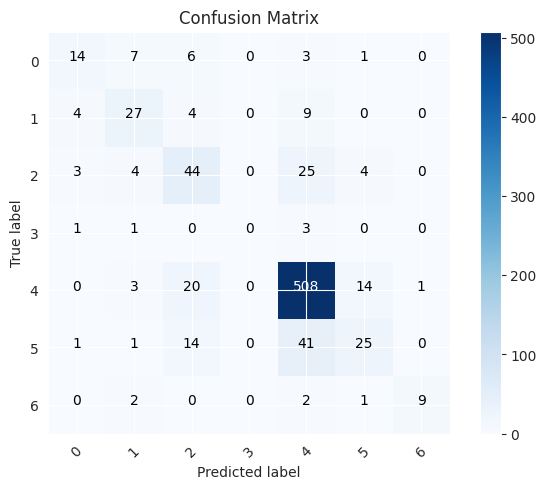

In [97]:
# Function to plot the confusion matrix
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion Matrix',
                          cmap=plt.cm.Blues):
    """
    This function displays the confusion matrix.
    Set `normalize=True` to display percentages instead of raw counts.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    # Set threshold to adjust text color
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], '.2f') if normalize else cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Predict the labels for the validation data
Y_pred = model.predict(x_validate)

# Convert predictions and true labels from one-hot to class indices
Y_pred_classes = np.argmax(Y_pred, axis=1)
Y_true = np.argmax(y_validate, axis=1)

# Compute the confusion matrix
confusion_mtx = confusion_matrix(Y_true, Y_pred_classes)

# Plot the confusion matrix
plot_confusion_matrix(confusion_mtx, classes=range(7))


63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 289ms/step


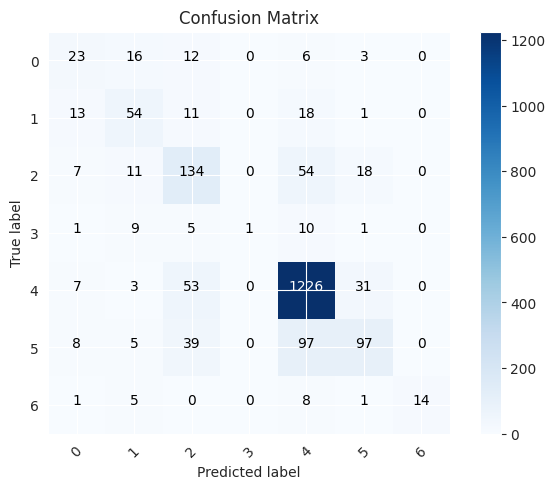

In [98]:
# Generate predictions for the test data
predicted_probabilities = model.predict(x_test)

# Determine the predicted class labels
predicted_labels = np.argmax(predicted_probabilities, axis=1)

# Extract the actual class labels from one-hot encoded format
true_labels = np.argmax(y_test, axis=1)

# Create the confusion matrix
cmatrix = confusion_matrix(true_labels, predicted_labels)

# Display the confusion matrix using a custom plotting function
plot_confusion_matrix(cmatrix, classes=list(range(7)))
